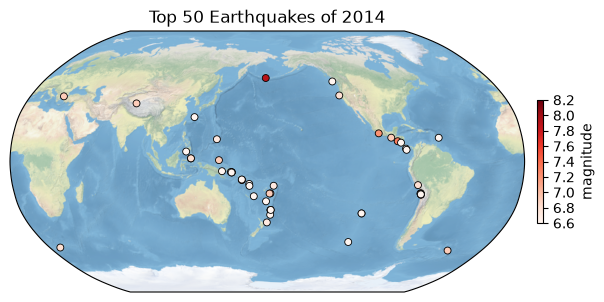

In [57]:
# 1
# 导入模块
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.feature as cfeature

# 读取文件，删去缺失值，排序并获取震级前50的数据
df = pd.read_csv("usgs_earthquakes.csv")
df = df.dropna(subset=["mag", "longitude", "latitude"])
# kind="mergesort"稳定排序，因为 mag > 6.5 的 39 条，mag == 6.5 有 15 条，加起来54条，多出4条，假如不限定排序，每次得出的数据值会不一样
top50 = df.sort_values("mag", ascending=False, kind="mergesort").head(50)    

# 新建画布，使用Robinson 投影，central_longitude=180 让太平洋居中，符合图例
fig = plt.figure(figsize=(8, 4), dpi=100)
proj = ccrs.Robinson(central_longitude=180)
ax = plt.axes(projection=proj)
# 添加地球背景图像
ax.stock_img()

# 将数据以散点的方式设置在地图上
sc = ax.scatter(
    top50["longitude"],                  # x 是经度
    top50["latitude"],                   # y 是纬度
    c=top50["mag"],                      # 颜色代表震级
    cmap="Reds",                         # 颜色由浅到深红，最小值接近白色
    vmin=6.6, vmax=8.2,                  # 设置颜色范围，和色标一致
    s=25,                                # 设置散点大小
    edgecolors="black", linewidths=0.6,  # 散点边框为黑色，线宽0.6
    transform=ccrs.PlateCarree(),        # 采用原始数据的经纬度
)

# 绘制色标
cbar = fig.colorbar(
    sc, ax=ax,
    shrink=0.4,                                                # 色标占地图高度的40%
    pad=0.02,                                                  # 色条与地图的间距
    ticks=[6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2],       # 色条刻度
)
# 色标标题
cbar.set_label("magnitude")
# 结果图标题
ax.set_title("Top 50 Earthquakes of 2014")
plt.show()


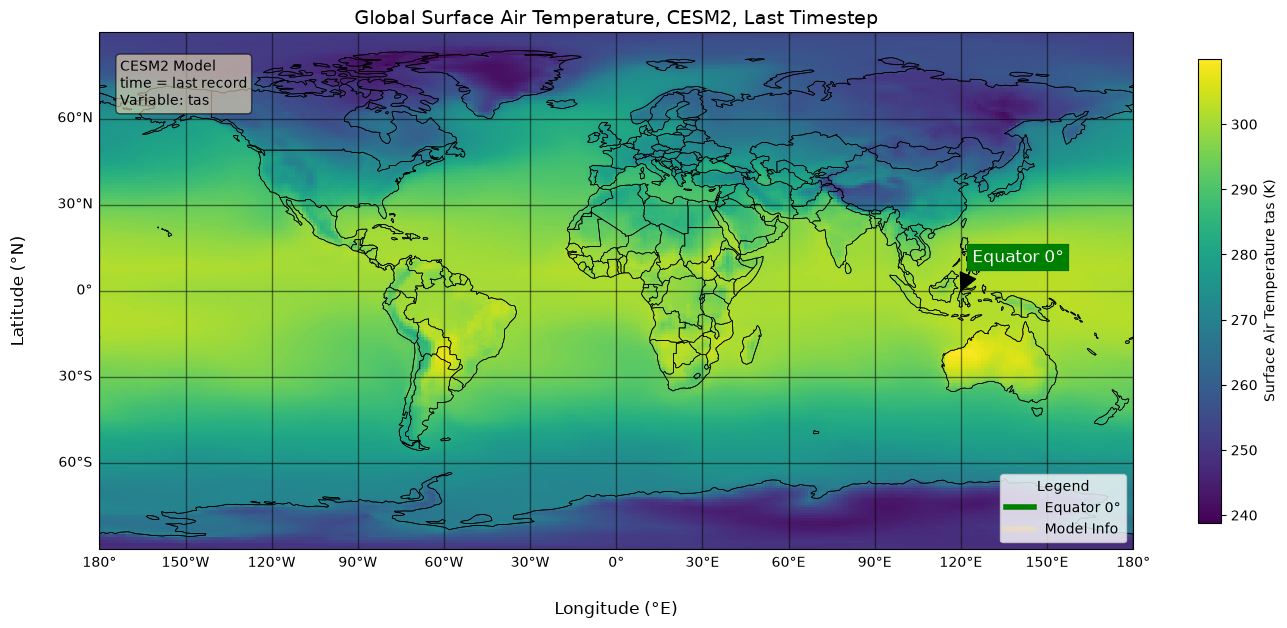

In [58]:
# 2.1
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 读取数据，mask_and_scale=False 关闭自动填充值的警告
ds = xr.open_dataset("CESM2_200001-201412(1).nc", mask_and_scale=False)
# 已知 CESM 缺失值标记为极大值 1e20，想要使用的数据变量为 tas，获取除去缺失值所有时间的tas数据
ds["tas"] = ds.tas.where(ds.tas < 1e19)
surface_T = ds.tas.isel(time=-1)

# 新建画布以及设置投影
plt.figure(figsize=(14,7), dpi=100)
proj = ccrs.PlateCarree()
ax = plt.axes(projection=proj)

# 绘制温度填色场，确立经纬度坐标，色条大小以及标题
im = surface_T.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    add_colorbar=True,
    cbar_kwargs={
        'shrink': 0.7,
        'label': 'Surface Air Temperature tas (K)',
        'pad': 0.05
    }
)

# 添加国界和海岸线
ax.add_feature(cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_0_countries',
    scale='110m',
    facecolor='none',
    edgecolor='black',
    linewidth=0.5
))
ax.add_feature(cfeature.COASTLINE, lw=0.5)

# 画出经纬线，显示X轴Y轴刻度
gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=1, color='black', alpha=0.5)
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 30))
gl.bottom_labels = True
gl.left_labels = True
 
# 添加结果图标题以及X轴Y轴标题
ax.set_title("Global Surface Air Temperature, CESM2, Last Timestep", fontsize=14)
ax.text(0.5, -0.10, "Longitude (°E)", ha="center", va="top", transform=ax.transAxes, fontsize=12)
ax.text(-0.07, 0.5, "Latitude (°N)", ha="right", va="center", transform=ax.transAxes, fontsize=12, rotation=90)

# 添加赤道箭头标注，设置箭头指向和文本位置、颜色等
plt.annotate('Equator 0°', 
             xy=(120, 0),                
             xytext=(140, 10),
             bbox=dict(boxstyle='square', fc='green', linewidth=0.1),
             arrowprops=dict(facecolor='black', shrink=0.01, width=0.1),
             fontsize=12, color='white', horizontalalignment='center',
             transform=ccrs.PlateCarree()) # 补上投影，防止位置飘移

# 设置文本框
textstr = "CESM2 Model\ntime = last record\nVariable: tas"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.6)
ax.text(0.02, 0.95, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

# 设置图例以及确认图例放置位置
from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='green', lw=4),
    Line2D([0], [0], color='wheat', lw=4, alpha=0.6)
]
ax.legend(custom_lines, ['Equator 0°', 'Model Info'], loc="lower right", title="Legend")

plt.tight_layout()
plt.show()

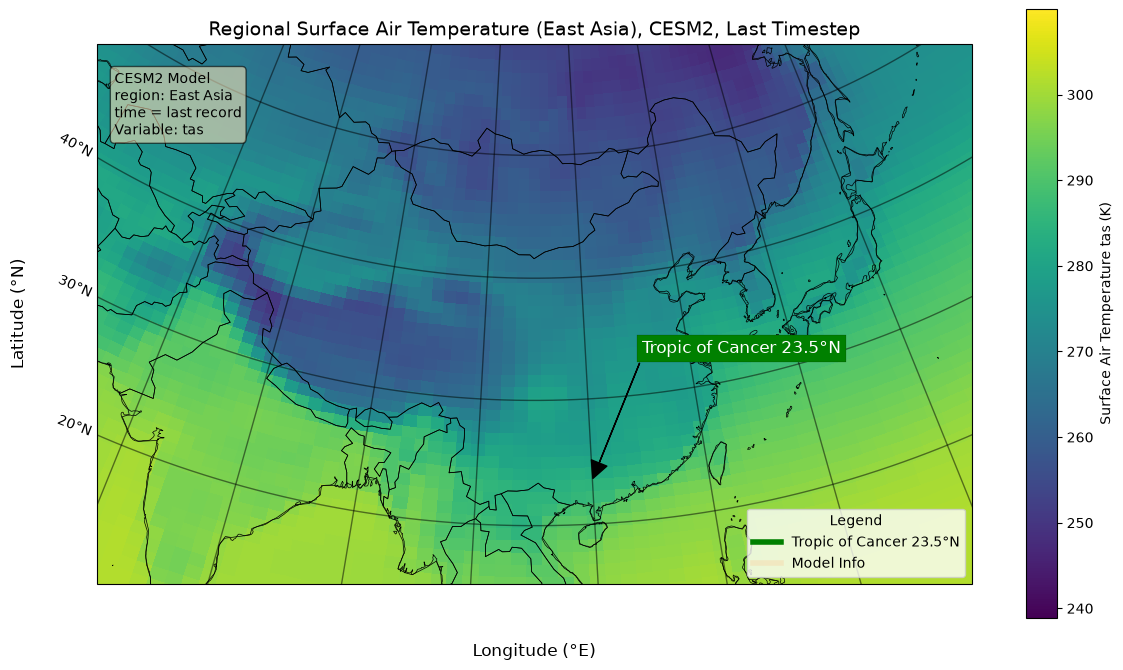

In [59]:
# 2.2 仍然导入模块读取数据，不然有可能报错
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ds = xr.open_dataset("CESM2_200001-201412(1).nc", mask_and_scale=False)
ds["tas"] = ds.tas.where(ds.tas < 1e19)
surface_T = ds.tas.isel(time=-1)

# 新建画布以及设置投影，确认画图区域
plt.figure(figsize=(12,9), dpi=100)
proj = ccrs.LambertConformal(central_longitude=105, central_latitude=35)
ax = plt.axes(projection=proj)
# 东亚区域范围
ax.set_extent([70, 140, 15, 55], crs=ccrs.PlateCarree())

# 绘制温度填色场，确立经纬度坐标，色条大小以及标题
im = surface_T.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    add_colorbar=True,
    cbar_kwargs={
        'shrink': 0.7,
        'label': 'Surface Air Temperature tas (K)',
        'pad': 0.05
    }
)

# 添加国界和海岸线
ax.add_feature(cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_0_countries',
    scale='110m',
    facecolor='none',
    edgecolor='black',
    linewidth=0.5
))
ax.add_feature(cfeature.COASTLINE, lw=0.5)

# 画出经纬线，显示X轴Y轴刻度
gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=1, color='black', alpha=0.5)
gl.ylocator = mticker.FixedLocator(np.arange(20, 56, 10))
gl.xlocator = mticker.FixedLocator(np.arange(70, 141, 10))
gl.bottom_labels = True
gl.left_labels = True

# 添加结果图标题以及X轴Y轴标题
ax.set_title("Regional Surface Air Temperature (East Asia), CESM2, Last Timestep", fontsize=14)
ax.text(0.5, -0.11, "Longitude (°E)", ha="center", va="top", transform=ax.transAxes, fontsize=12)
ax.text(-0.08, 0.5, "Latitude (°N)", ha="right", va="center", transform=ax.transAxes, fontsize=12, rotation=90)

# 添加赤道箭头标注，设置箭头指向和文本位置、颜色等
plt.annotate('Tropic of Cancer 23.5°N',
             xy=(110, 23.5),
             xytext=(125, 32),
             bbox=dict(boxstyle='square', fc='green', linewidth=0.1),
             arrowprops=dict(facecolor='black', shrink=0.01, width=0.1),
             fontsize=12, color='white', horizontalalignment='center',
             transform=ccrs.PlateCarree())

# 设置文本框
textstr = "CESM2 Model\nregion: East Asia\ntime = last record\nVariable: tas"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.6)
ax.text(0.02, 0.95, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

# 设置图例
from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='green', lw=4),
    Line2D([0], [0], color='wheat', lw=4, alpha=0.6)
]
ax.legend(custom_lines, ['Tropic of Cancer 23.5°N', 'Model Info'], loc="lower right", title="Legend")

plt.tight_layout()
plt.show()
